NAME- UJJAWAL CHAUHAN
SEC-'B' '62'
CU24250259
LABSHEET -10

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


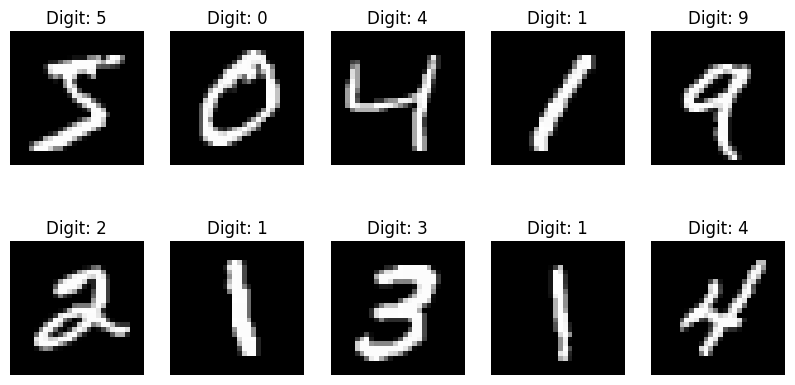

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')

plt.show()

In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [ ]:
X_val = X_train[-5000:]
y_val = y_train[-5000:]

X_train_new = X_train[:-5000]
y_train_new = y_train[:-5000]

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (55000, 28, 28, 1)
Validation: (5000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64
)

Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 52s 58ms/step - accuracy: 0.9200 - loss: 0.2617 - val_accuracy: 0.9826 - val_loss: 0.0615
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 79s 56ms/step - accuracy: 0.9727 - loss: 0.0930 - val_accuracy: 0.9886 - val_loss: 0.0387
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9797 - loss: 0.0690 - val_accuracy: 0.9910 - val_loss: 0.0386
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 84s 56ms/step - accuracy: 0.9829 - loss: 0.0557 - val_accuracy: 0.9898 - val_loss: 0.0348
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 80s 54ms/step - accuracy: 0.9857 - loss: 0.0470 - val_accuracy: 0.9906 - val_loss: 0.0361
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 46s 53ms/step - accuracy: 0.9881 - loss: 0.0398 - val_accuracy: 0.9906 - val_loss: 0.0338
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 83s 55ms/step - accuracy: 0.9895 - loss: 0.0345 - val_accuracy: 0.9916 - val_loss: 0.0299
Epoch 8/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 46s 53ms/step - accuracy: 0.9898 - loss: 0.0309 - 

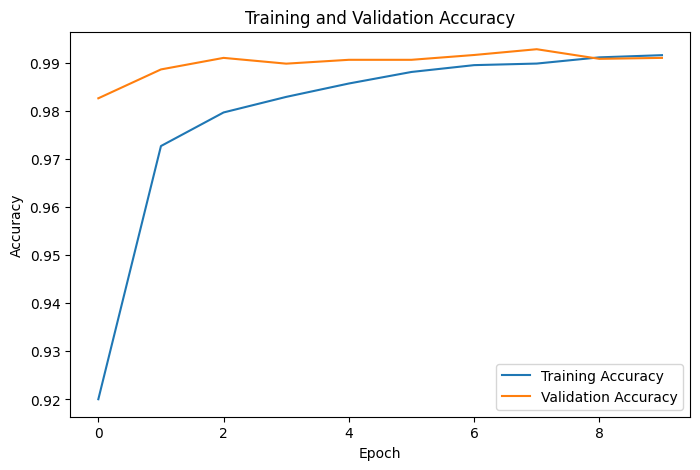

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

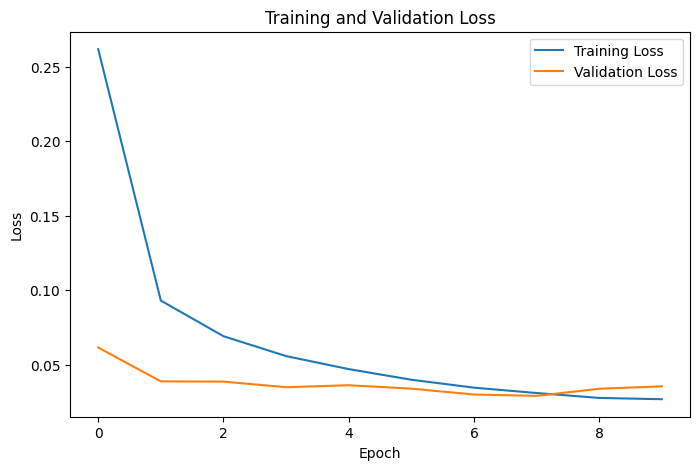

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9916 - loss: 0.0278
Test Loss: 0.02782781980931759
Test Accuracy: 0.991599977016449


In [ ]:
predictions = model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

print("Actual:", y_test[:10])
print("Predicted:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Actual: [7 2 1 0 4 1 4 9 5 9]
Predicted: [7 2 1 0 4 1 4 9 5 9]


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      1.00      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      1.00      1.00       982
           5       0.98      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       1.00      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 979    0    0    0    0    0    0    1    0    0]
 [   0 1133    0    0    0    1    1    0    0    0]
 [   1    0 1027    0    0    0    0    4    0    0]
 [   0    0    2 1004    0    3    0    0    1    0]
 [   0    0    0    0  978    0    2    0    0    2]
 [   1    0    1    3    0  886    1    0    0    0]
 [   7    2    0    0    1    3  944    0    1    0]
 [   0    2    3    1    0    0    0 1021    1    0]
 [   6    1    2    1    1    2    0    2  957    2]
 [   3    1    0    0    3    6    0    5    4  987]]


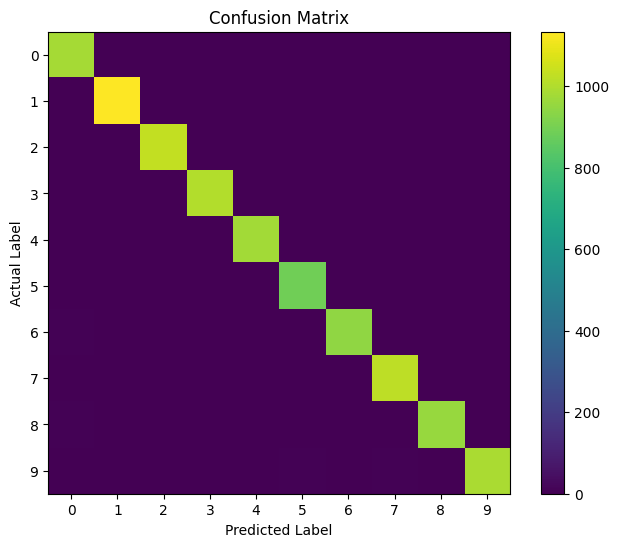

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(cm)
plt.colorbar()

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()

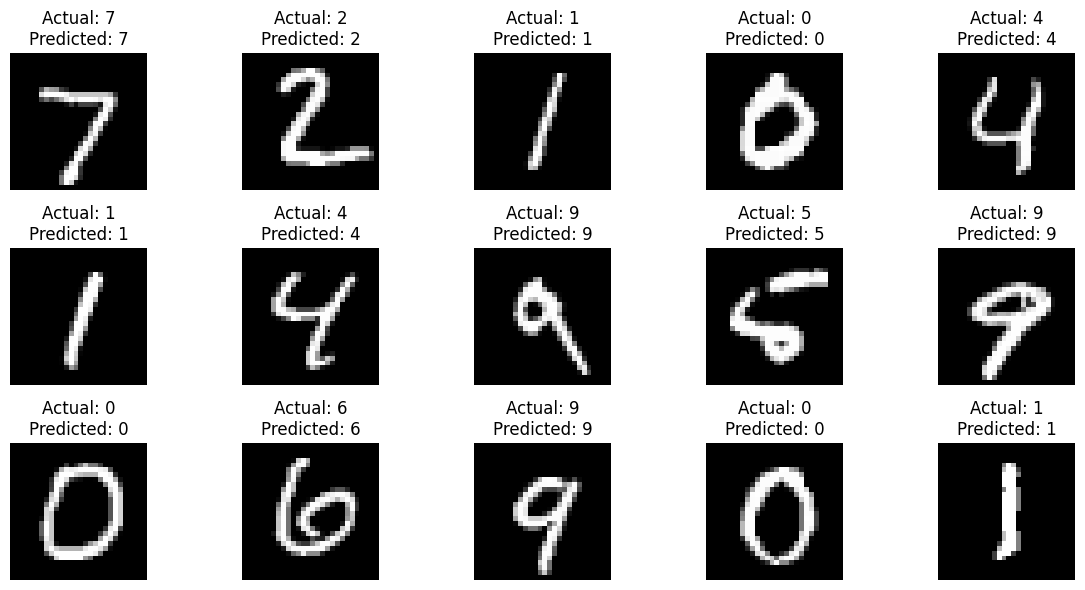

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Actual: " + str(y_test[i]) +
              "\nPredicted: " + str(y_pred[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
wrong = np.where(y_pred != y_test)[0]

print("Number of misclassified images:", len(wrong))

Number of misclassified images: 84


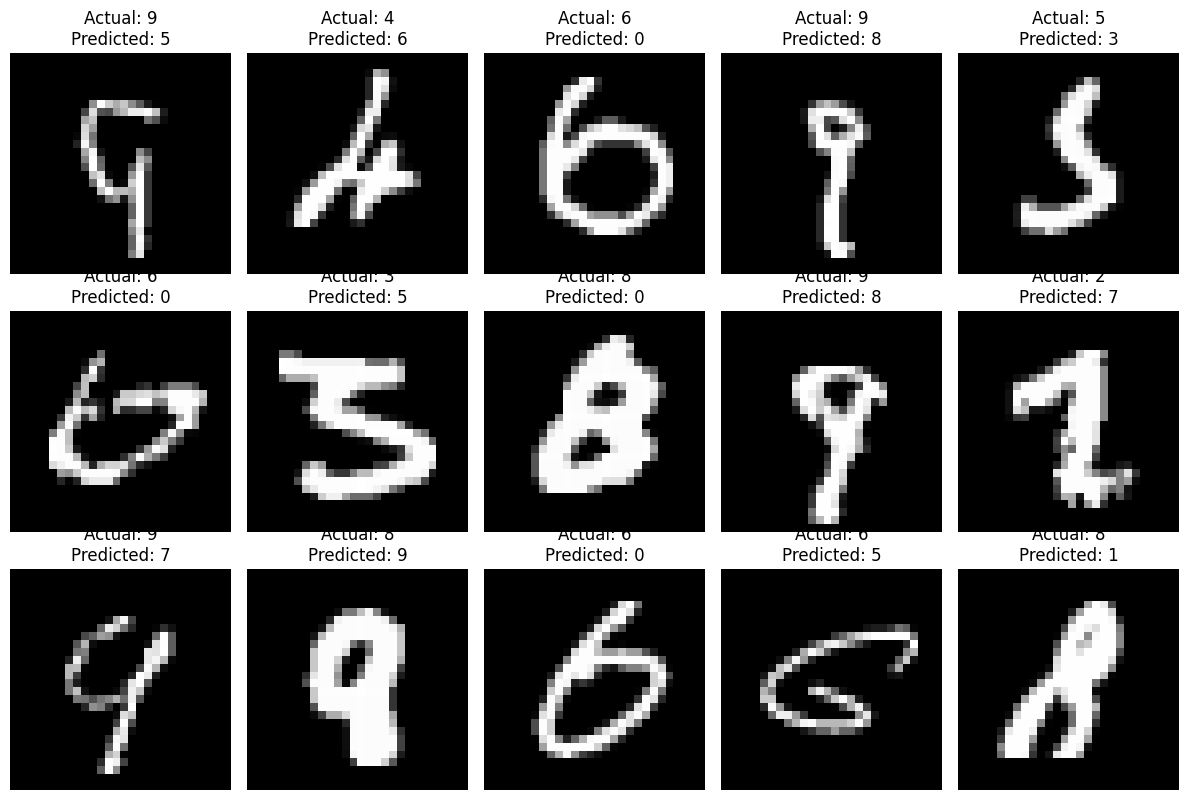

In [ ]:
plt.figure(figsize=(12, 8))

for i in range(min(15, len(wrong))):
    index = wrong[i]

    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[index].reshape(28, 28), cmap='gray')
    plt.title("Actual: " + str(y_test[index]) +
              "\nPredicted: " + str(y_pred[index]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model.save("mnist_cnn_model.keras")